In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [53]:
# Load Dataset
df = pd.read_excel("UPI_Transaction_Analysis_1000.xlsx")
df

# Display First 5 Records
print(df.head())

  Transaction_ID Transaction_Date Transaction_Time User_ID      City  \
0      UPI100001       2026-01-28         19:52:46   U0186    Satara   
1      UPI100002       2026-08-24         17:03:40   U0249    Nagpur   
2      UPI100003       2026-07-18         13:23:55   U0193    Satara   
3      UPI100004       2026-05-14         21:27:57   U0179  Kolhapur   
4      UPI100005       2026-05-12         03:47:42   U0141    Nagpur   

        Bank_Name Payment_Method  Transaction_Amount Transaction_Status  \
0       Axis Bank        QR Code             2609.51            Success   
1  Bank of Baroda        QR Code             7627.06            Success   
2       HDFC Bank  Mobile Number             1735.11             Failed   
3      ICICI Bank        QR Code             9409.43            Success   
4  Kotak Mahindra        QR Code            13129.74            Success   

  Device_Type  
0         iOS  
1     Android  
2     Android  
3         iOS  
4     Android  


In [62]:
# Total Rows and Columns
print("Dataset Shape:", df.shape)

# Dataset Information
print(df.info())

# Missing Values
print(df.isnull().sum())

# Duplicate Records
print("Duplicates:", df.duplicated().sum())

# Statistical Summary
print(df.describe())

Dataset Shape: (1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      1000 non-null   object        
 1   Transaction_Date    1000 non-null   datetime64[ns]
 2   Transaction_Time    1000 non-null   object        
 3   User_ID             1000 non-null   object        
 4   City                1000 non-null   object        
 5   Bank_Name           1000 non-null   object        
 6   Payment_Method      1000 non-null   object        
 7   Transaction_Amount  1000 non-null   float64       
 8   Transaction_Status  1000 non-null   object        
 9   Device_Type         1000 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(8)
memory usage: 78.2+ KB
None
Transaction_ID        0
Transaction_Date      0
Transaction_Time      0
User_ID               0
City                  0

In [64]:

print("Total Transactions:", len(df))


print("Total Amount : ", df['Transaction_Amount'].sum())


Success=df[df["Transaction_Status"]=="Success"]
print("Successful Transactions :",len(Success))


Failed=df[df["Transaction_Status"]=="Failed"]
print("Failed Transactions :",len(Failed))


print(df['Transaction_Status'].value_counts())


City_analysis=df.groupby("City")['Transaction_Amount'].sum()
print(City_analysis.sort_values(ascending=False))

bank_analysis=df.groupby("Bank_Name")['Transaction_Amount'].sum()
print(bank_analysis.sort_values(ascending=False))

print("Average Amount : ",df['Transaction_Amount'].mean())

Total Transactions: 1000
Total Amount :  7452484.46
Successful Transactions : 883
Failed Transactions : 77
Transaction_Status
Success    883
Failed      77
Pending     40
Name: count, dtype: int64
City
Mumbai        1088704.82
Kolhapur      1054747.29
Nagpur         928242.88
Nashik         918060.67
Satara         894697.67
Aurangabad     889043.10
Thane          862971.27
Pune           816016.76
Name: Transaction_Amount, dtype: float64
Bank_Name
Axis Bank         1336758.75
Bank of Baroda    1286558.93
HDFC Bank         1261613.15
ICICI Bank        1229156.58
Kotak Mahindra    1178368.89
SBI               1160028.16
Name: Transaction_Amount, dtype: float64
Average Amount :  7452.48446


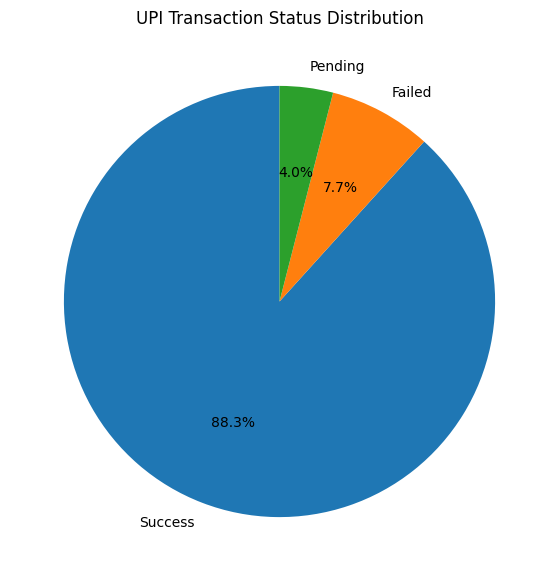

In [56]:
status_count = df["Transaction_Status"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(
    status_count.values,
    labels=status_count.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("UPI Transaction Status Distribution")
plt.show()

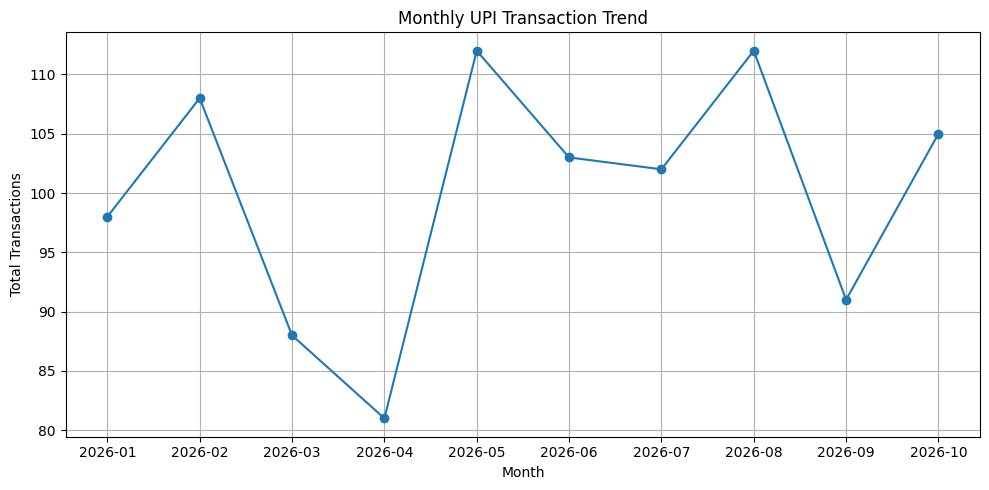

In [57]:
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"])

monthly_txn = df.groupby(
    df["Transaction_Date"].dt.to_period("M")
).size()

monthly_txn.index = monthly_txn.index.astype(str)

plt.figure(figsize=(10,5))

plt.plot(monthly_txn.index, monthly_txn.values, marker="o")

plt.title("Monthly UPI Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Total Transactions")

plt.grid(True)
plt.tight_layout()
plt.show()

Chart 3: Bank-wise Transaction Analysis (Bar Chart)

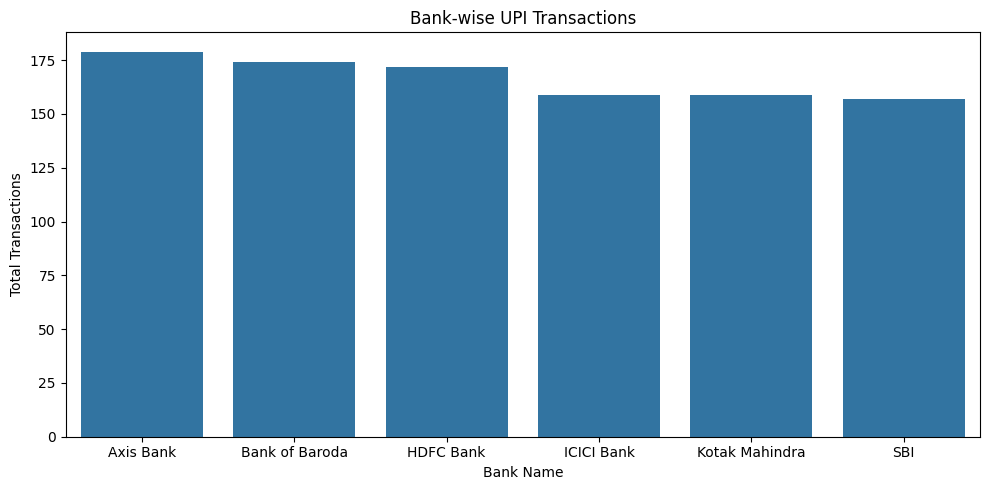

In [58]:
bank_count = df["Bank_Name"].value_counts()
plt.figure(figsize=(10,5))
sns.barplot(x=bank_count.index, y=bank_count.values)

plt.title("Bank-wise UPI Transactions")
plt.xlabel("Bank Name")
plt.ylabel("Total Transactions")

plt.tight_layout()
plt.show()

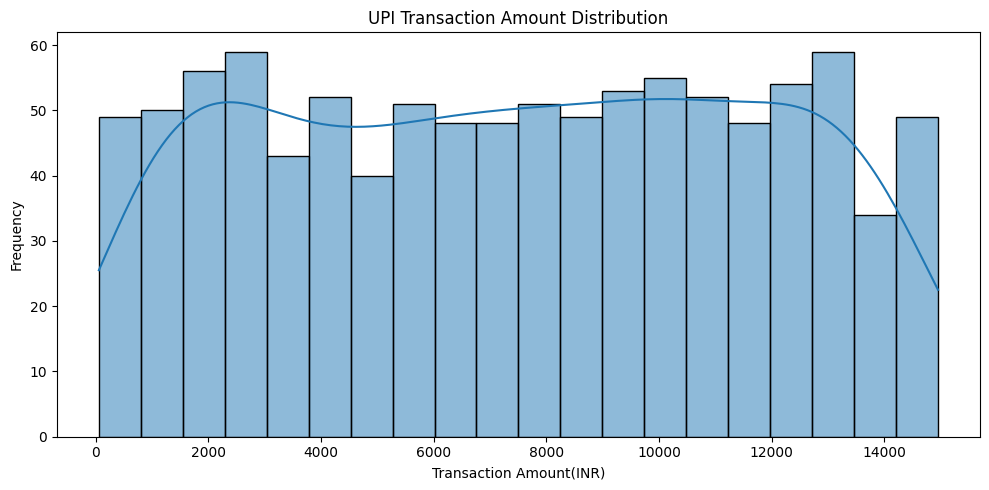

In [59]:
plt.figure(figsize=(10,5))
sns.histplot(df["Transaction_Amount"], bins=20, kde=True)

plt.title("UPI Transaction Amount Distribution")
plt.xlabel("Transaction Amount(INR)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

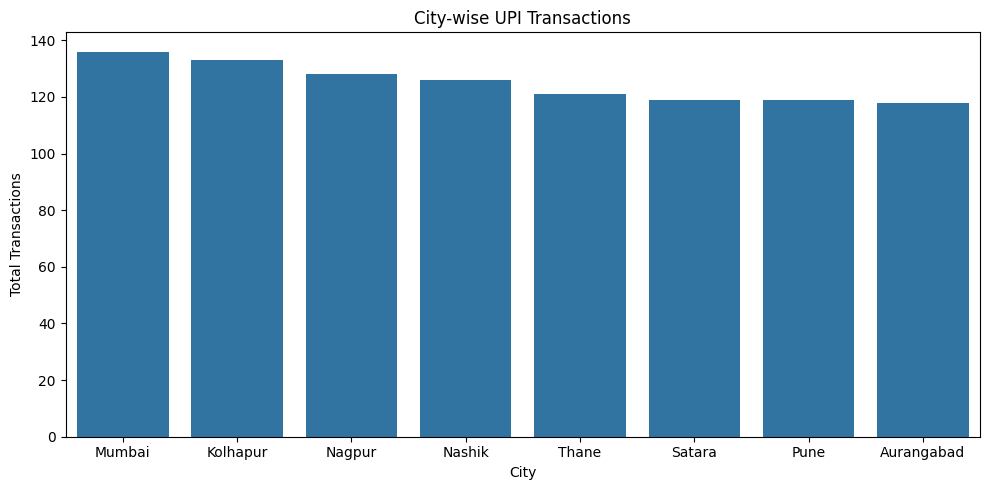

In [60]:
plt.figure(figsize=(10,5))
city_count = df["City"].value_counts()

sns.barplot(x=city_count.index, y=city_count.values)

plt.title("City-wise UPI Transactions")
plt.xlabel("City")
plt.ylabel("Total Transactions")

plt.tight_layout()
plt.show()

In [61]:
# Success Rate
success_rate = (len(Success) / len(df)) * 100

# Failed Rate
failed_rate = (len(Failed) / len(df)) * 100

# Top City and Bank by Transaction Count
top_city = df["City"].value_counts().idxmax()
top_bank = df["Bank_Name"].value_counts().idxmax()

print("Success Rate:", round(success_rate,2), "%")
print("Failed Rate:", round(failed_rate, 2), "%")
print("Top City:", top_city)
print("Top Bank:", top_bank)

Success Rate: 88.3 %
Failed Rate: 7.7 %
Top City: Mumbai
Top Bank: Axis Bank
